# 06 — Varredura multivariada sintética extensa, com dependência e suporte controlados

> **Versão SPW=13.882494684620836.** Esta suíte usa um novo retreino com `scale_pos_weight=13.882494684620836` e limiar fixo `0,50`. O desenho do `model_final.ipynb` foi mantido, exceto pelo peso de classe solicitado. O modelo congelado e sua configuração estão em `models/`; os dados de entrada devem estar em `data/raw/`.


## Pergunta e interpretação correta

Este notebook gera **2.048 perturbações multivariadas dentro do suporte observado no treino** e **128 cenários deliberadamente fora dele**. Todas partem de linhas reais de `cs-test.csv`, cuja coluna de desfecho está vazia. A varredura mede **drift de entrada, mudança do score e decisões que mudam**. Ela **não mede AUC, AP, recall, Brier nem queda de desempenho**, porque o desfecho contrafactual de uma pessoa após alterar seus atributos não é conhecido. Para tolerância de *desempenho* com rótulos, combine este diagnóstico com os experimentos de reponderação de linhas do holdout rotulado. Não interprete estabilidade de score como prova de desempenho estável.

O `model_class` da sessão original não foi serializado em `model_final.ipynb`; usamos o Booster **reconstruído e congelado** em `model_class_retreinado.json`. Nenhum cenário retreina o modelo. A amostra operacional tem 5.000 linhas estratificadas apenas por sorteio aleatório reproduzível de `cs-test.csv`; cenários selecionados são repetidos nas 101.503 linhas para verificar a sensibilidade da amostragem.

### Princípios do desenho

1. Recuperar o split original e **mínimo/máximo de cada feature apenas no treino**.
2. Ajustar marginais empíricas e uma cópula gaussiana de postos no treino. Os atributos categóricos discretos (idade e contagens) saem pela função quantil empírica e permanecem inteiros. A máscara original de faltantes é preservada.
3. Escolher combinações de 2–8 variáveis e intensidades/direções com Sobol embaralhado. As outras variáveis recebem a resposta condicional da cópula: para variáveis alteradas A e demais B, `Δz_B = R_BA (R_AA)^−1 Δz_A`. O resíduo condicional de cada linha permanece o mesmo. A técnica aproxima dependências de posto; não estabelece causalidade nem garante todas as restrições de negócio.
4. Gerar o candidato **bruto** por inversão empírica com extrapolação explícita nas caudas contínuas. Nos 2.048 cenários internos, truncar ao intervalo `[min_treino, max_treino]` e registrar a proporção efetivamente truncada. Nos 128 cenários externos, introduzir uma violação controlada acima do máximo ou abaixo do mínimo em uma variável contínua e **não truncar**. Como os mínimos de utilização, dívida e renda no treino são zero, os cenários abaixo do mínimo geram valores negativos: são **testes de validação de entrada/software**, não candidatos plausíveis a tomadores.
5. Auditar PSI por variável, distância de Wasserstein 1D normalizada, diferença de correlações de Spearman, faltantes, integralidade, fração fora de suporte, deslocamento de score e reversões do cutoff 0,50.

Fontes: [SciPy Sobol](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.qmc.Sobol.html), [SciPy Wasserstein](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wasserstein_distance.html), [modelo de cópula para dados mistos](https://pmc.ncbi.nlm.nih.gov/articles/PMC3753118/), [limitações de cópulas com marginais discretas](https://www.sciencedirect.com/science/article/abs/pii/S0165011420304528), [predição com Booster XGBoost](https://xgboost.readthedocs.io/en/release_3.1.0/python/python_api.html). Usamos Sobol com `2^11` pontos para manter a propriedade de balanceamento descrita na documentação.

In [1]:
from pathlib import Path

# Resolve o projeto tanto pelo Jupyter aberto em notebooks/ quanto pelo executor.
_inicio = Path.cwd().resolve()
PROJECT_ROOT = next(
    (p for p in (_inicio, *_inicio.parents)
     if (p / "models" / "manifesto_modelo.json").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Não encontrei models/manifesto_modelo.json. Abra o projeto clonado.")
DATA_DIR_PROJECT = PROJECT_ROOT / "data" / "raw"
MODEL_DIR = PROJECT_ROOT / "models"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
for _nome in ("cs-training.csv", "cs-test.csv"):
    if not (DATA_DIR_PROJECT / _nome).is_file():
        raise FileNotFoundError(
            f"Falta {DATA_DIR_PROJECT / _nome}. Veja README.md, seção Dados."
        )


In [2]:
from pathlib import Path
import json, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from scipy.special import expit, ndtr, ndtri
from scipy.stats import qmc
from sklearn.model_selection import train_test_split
from IPython.display import display

SEED = 33
N_AMOSTRA = 5_000
N_IN = 2_048
N_OUT = 128
BATCH = 16
CUTOFF = 0.50
P = DATA_DIR_PROJECT
DATA_DIR = next((d for d in (P, P.parent) if (d / "cs-training.csv").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Coloque os CSVs em data/raw/ e execute a partir da raiz do projeto ou de notebooks/.")
BASE = TABLES_DIR
FEATURES = [
    'RevolvingUtilizationOfUnsecuredLines', 'age',
    'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome',
    'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate',
    'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse',
    'NumberOfDependents'
]
FEATURE_SHORT = ['Utilização','Idade','Atraso 30–59','Dívida/renda','Renda',
                 'Linhas/cred.','Atraso 90+','Imobiliário','Atraso 60–89','Dependentes']
CONTINUAS = np.array([0, 3, 4], dtype=int)
DISCRETAS = np.array([1, 2, 5, 6, 7, 8, 9], dtype=int)
REGIMES = ['localização', 'cauda superior', 'cauda inferior', 'coorte correlacionada']
assert (MODEL_DIR / 'model_class_retreinado.json').exists()
assert (DATA_DIR/'cs-training.csv').exists() and (DATA_DIR/'cs-test.csv').exists()
sns.set_theme(style='whitegrid', context='notebook')
np.set_printoptions(precision=3, suppress=True)
print('XGBoost', xgb.__version__, '| amostra', N_AMOSTRA, '| Sobol interno', N_IN, '| externo', N_OUT)

XGBoost 3.0.0 | amostra 5000 | Sobol interno 2048 | externo 128


In [3]:
# Verifica que o modelo, o manifesto e a configuração deste estudo coincidem.
import hashlib as _hashlib
import json as _json
_manifesto_versao = _json.loads(
    (MODEL_DIR / "manifesto_modelo.json").read_text(encoding="utf-8")
)
assert abs(_manifesto_versao["params_fornecidos"]["scale_pos_weight"]
           - 13.882494684620836) < 1e-12
assert _manifesto_versao["cutoff"] == 0.5
assert _manifesto_versao["features"] == FEATURES
_arquivo_modelo_versao = MODEL_DIR / "model_class_retreinado.json"
assert _hashlib.sha256(_arquivo_modelo_versao.read_bytes()).hexdigest() == \
       _manifesto_versao["model_sha256"], "Booster e manifesto divergentes."
print("Modelo validado:", _manifesto_versao["variant"])


Modelo validado: metricas_brier_auc_prauc_ks_grade_5a50


## 1. Fonte, split e linha de base

Reproduzimos exatamente as duas chamadas de `train_test_split` do notebook final: 15% reservado para teste, depois 17,65% do restante reservado para validação, ambas sem estratificação, com semente 33. Os limites são calculados **somente nas 104.996 linhas de treino**. Se `cs-test.csv` já trouxer valores além desses limites, a linha de base das simulações é truncada uma vez; a tabela a seguir quantifica essa intervenção inicial. O CSV original não é modificado.

In [4]:
treino = pd.read_csv(DATA_DIR/'cs-training.csv').drop(columns='Unnamed: 0')
cs_test = pd.read_csv(DATA_DIR/'cs-test.csv').drop(columns='Unnamed: 0')
assert treino['SeriousDlqin2yrs'].notna().all()
assert cs_test['SeriousDlqin2yrs'].isna().all(), 'cs-test não deve conter rótulos.'
assert list(treino.drop(columns='SeriousDlqin2yrs').columns) == FEATURES
assert list(cs_test.drop(columns='SeriousDlqin2yrs').columns) == FEATURES
X_tv, X_hold, y_tv, y_hold = train_test_split(
    treino[FEATURES], treino['SeriousDlqin2yrs'], test_size=.15, random_state=SEED)
X_train, X_val, _, _ = train_test_split(X_tv, y_tv, test_size=.1765, random_state=SEED)
assert X_train.shape == (104_996, 10)
lo = X_train.min().to_numpy(dtype=float)
hi = X_train.max().to_numpy(dtype=float)
assert np.all(np.isfinite(lo)) and np.all(np.isfinite(hi))
assert np.all(hi > lo)

rng = np.random.default_rng(SEED+2026)
idx = np.sort(rng.choice(len(cs_test), N_AMOSTRA, replace=False))
X_origem = cs_test.iloc[idx][FEATURES].to_numpy(dtype=float)
X0 = np.clip(X_origem, lo, hi)
M0 = np.isnan(X0)
fonte_fora = np.isfinite(X_origem) & ((X_origem < lo) | (X_origem > hi))

model_class = xgb.Booster()
model_class.load_model(str(MODEL_DIR / 'model_class_retreinado.json'))
assert model_class.feature_names == FEATURES
model_class.set_param({'device':'cpu'})
def prever(a):
    return model_class.predict(xgb.DMatrix(a, feature_names=FEATURES, missing=np.nan),
                               iteration_range=(0, model_class.num_boosted_rounds()))
p0 = prever(X0)
base_score = {'media':float(p0.mean()), 'mediana':float(np.median(p0)),
              'p90':float(np.quantile(p0,.9)), 'taxa_ge_050':float((p0>=CUTOFF).mean())}
limites = pd.DataFrame({'variavel':FEATURES, 'min_treino':lo, 'max_treino':hi,
                        'faltantes_cs_test_%':100*cs_test[FEATURES].isna().mean().to_numpy(),
                        'origem_fora_na_amostra_%':100*fonte_fora.mean(axis=0)})
display(limites.round(3))
print('Baseline da amostra suportada:', base_score)
print('Células de origem truncadas antes dos cenários:', int(fonte_fora.sum()),
      'de', int(np.isfinite(X_origem).sum()))

,variavel,min_treino,max_treino,faltantes_cs_test_%,origem_fora_na_amostra_%
0,RevolvingUtilizationOfUnsecuredLines,0.0,50708.0,0.000,0.0
1,age,0.0,109.0,0.000,0.0
2,NumberOfTime30-59DaysPastDueNotWorse,0.0,98.0,0.000,0.0
3,DebtRatio,0.0,329664.0,0.000,0.0
4,MonthlyIncome,0.0,3008750.0,19.805,0.0
5,NumberOfOpenCreditLinesAndLoans,0.0,58.0,0.000,0.0
6,NumberOfTimes90DaysLate,0.0,98.0,0.000,0.0
7,NumberRealEstateLoansOrLines,0.0,54.0,0.000,0.0
8,NumberOfTime60-89DaysPastDueNotWorse,0.0,98.0,0.000,0.0
9,NumberOfDependents,0.0,13.0,2.587,0.0


Baseline da amostra suportada: {'media': 0.3234098553657532, 'mediana': 0.2283422350883484, 'p90': 0.7448281049728394, 'taxa_ge_050': 0.2428}
Células de origem truncadas antes dos cenários: 0 de 48845


## 2. Calibrar a cópula de postos e as marginais empíricas

Para cada variável observada `x`, usamos sua posição entre os valores do treino, `u = (busca_esquerda + busca_direita)/(2n)`, e `z = Φ⁻¹(u)`. Empates discretos recebem posto médio. Faltantes entram como `z=0` apenas na estimação/propagação latente e são **restaurados como NaN** no final. A matriz de correlação é estimada em pares observados, regularizada e projetada ao cone positivo; a projeção e o preenchimento de faltantes são aproximações. A transformação inversa aplica o quantil empírico: degraus para idade/contagens, interpolação para variáveis contínuas. Valores latentes além dos extremos observados geram candidato bruto extrapolado com inclinação baseada nas caudas 0,5–5% e 95–99,5% do treino.

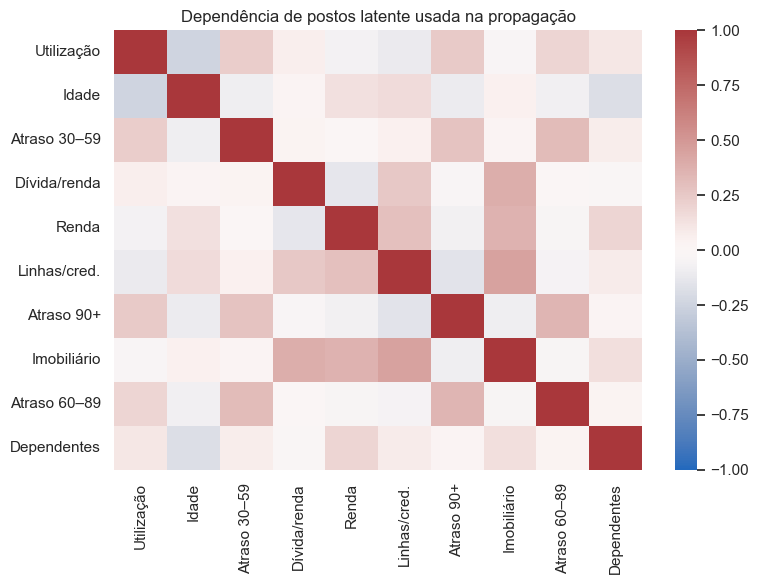

Autovalor mínimo da matriz regularizada: 0.3887


In [5]:
marginais = [np.sort(X_train[f].dropna().to_numpy(dtype=float)) for f in FEATURES]
z_min, z_max, escala_w1, raw_slopes = [], [], [], []
for j, m in enumerate(marginais):
    n = len(m)
    z_min.append(float(ndtri(.5/n)))
    z_max.append(float(ndtri(1-.5/n)))
    q005,q05,q95,q995 = np.quantile(m,[.005,.05,.95,.995])
    escala_w1.append(max(q95-q05, float(np.std(m)), 1.0))
    slope_lo = max((q05-q005)/(ndtri(.05)-ndtri(.005)), 1e-6)
    slope_hi = max((q995-q95)/(ndtri(.995)-ndtri(.95)), 1e-6)
    raw_slopes.append((slope_lo,slope_hi))
z_min=np.array(z_min); z_max=np.array(z_max); escala_w1=np.array(escala_w1)

def para_latente(a):
    z = np.zeros_like(a, dtype=float)
    for j, m in enumerate(marginais):
        obs=np.isfinite(a[:,j])
        x=a[obs,j]
        left=np.searchsorted(m,x,side='left')
        right=np.searchsorted(m,x,side='right')
        u=np.clip((left+right)/(2*len(m)), .5/len(m), 1-.5/len(m))
        z[obs,j]=ndtri(u)
    return z

def inversa_empirica_bruta(z, missing):
    out=np.empty_like(z)
    for j,m in enumerate(marginais):
        zz=z[:,j]
        u=ndtr(zz)
        n=len(m)
        if j in DISCRETAS:
            # Função quantil empírica escalonada; suporte observado inteiro.
            ix=np.minimum(np.floor(u*n).astype(int),n-1)
            out[:,j]=m[ix]
        else:
            grid=(np.arange(n)+.5)/n
            x=np.interp(u,grid,m)
            below=zz<z_min[j]; above=zz>z_max[j]
            if below.any():
                x[below]=m[0]+raw_slopes[j][0]*(zz[below]-z_min[j])
            if above.any():
                x[above]=m[-1]+raw_slopes[j][1]*(zz[above]-z_max[j])
            out[:,j]=x
    out[missing]=np.nan
    return out

R_raw=pd.DataFrame(para_latente(X_train.to_numpy(dtype=float)),columns=FEATURES)
R_raw[X_train[FEATURES].isna().to_numpy()]=np.nan
R=R_raw.corr().fillna(0).to_numpy()
np.fill_diagonal(R,1.)
R=.95*R+.05*np.eye(len(FEATURES))
ev,V=np.linalg.eigh(R)
R=(V*np.maximum(ev,.02))@V.T
d=np.sqrt(np.diag(R)); R=R/d[:,None]/d[None,:]
assert np.linalg.eigvalsh(R).min()>0
Z0=para_latente(X0)
eigval,eigvec=np.linalg.eigh(R)
pc1=eigvec[:,-1]
if pc1[0]<0: pc1=-pc1
coorte=(Z0@pc1)/max(np.std(Z0@pc1),1e-8)

fig,ax=plt.subplots(figsize=(8,6))
sns.heatmap(R,cmap='vlag',center=0,vmin=-1,vmax=1,xticklabels=FEATURE_SHORT,
            yticklabels=FEATURE_SHORT,ax=ax)
ax.set_title('Dependência de postos latente usada na propagação')
plt.tight_layout(); plt.show()
print('Autovalor mínimo da matriz regularizada:',np.linalg.eigvalsh(R).min().round(4))

## 3. Desenho amplo das intervenções

A sequência Sobol escolhe **combinações, sinais, magnitudes e alcance** sem limitar a varredura a perfis narrativos. Há 512 cenários por família interna: (i) deslocamento latente uniforme; (ii) maior intervenção na cauda superior; (iii) maior intervenção na cauda inferior; (iv) intervenção que cresce com um primeira componente latente da matriz de dependência, sem interpretação automática como risco. Entre 2 e 8 das 10 features são motores em cada cenário. As demais variáveis respondem segundo a regressão condicional gaussiana; isto evita mexer numa dimensão isoladamente enquanto o restante fica arbitrariamente fixo.

As 128 variações externas usam pelo menos um motor contínuo entre utilização, dívida/renda e renda, além de outros motores, com metade acima do máximo e metade abaixo do mínimo. As variações superiores são testes adversariais de extrapolação estatística; as inferiores, por atravessarem zero, são testes de validação de domínio. Nenhuma é uma população futura postulada como plausível. A semente, os motores e as intensidades de cada cenário ficam no CSV.

In [6]:
sob_in=qmc.Sobol(d=24,scramble=True,seed=SEED+91).random_base2(11)
sob_out=qmc.Sobol(d=24,scramble=True,seed=SEED+92).random_base2(7)

def especificacao(i, externo=False):
    u=(sob_out if externo else sob_in)[i]
    if not externo:
        k=2+min(int(7*u[0]),6)
        A=np.sort(np.argsort(u[1:11])[-k:])
        regime=REGIMES[i//512]
    else:
        k=2+min(int(4*u[0]),3)
        obrigatorio=CONTINUAS[i%len(CONTINUAS)]
        outros=[j for j in np.argsort(u[1:11])[::-1] if j!=obrigatorio][:k-1]
        A=np.sort(np.array([obrigatorio]+outros,dtype=int))
        regime='externo acima' if i%2==0 else 'externo abaixo'
    v=2*u[11:21]-1
    delta=np.sign(v[A])*(.15+2.6*np.abs(v[A]))*(.20+1.20*u[21])
    if externo:
        # A variável contínua obrigatória sempre é empurrada para a cauda testada.
        loc=np.where(A==obrigatorio)[0][0]
        delta[loc]=(1 if i%2==0 else -1)*(.8+2.2*u[22])
    return {'id':('EXT' if externo else 'INT')+f'{i+1:04d}',
            'externo':externo,'regime':regime,'A':A,'delta':delta,
            'slope':float(1+3*u[22]), 'u':u,
            'obrigatorio':int(obrigatorio) if externo else None,
            'cauda_frac':float(.03+.17*u[23]) if externo else np.nan}

especificacoes=[especificacao(i) for i in range(N_IN)] + [especificacao(i,True) for i in range(N_OUT)]
assert len(especificacoes)==2176
assert len({s['id'] for s in especificacoes})==2176
assert all(2<=len(s['A'])<=8 for s in especificacoes)
display(pd.DataFrame({'regime':[s['regime'] for s in especificacoes],
                      'n_motores':[len(s['A']) for s in especificacoes]})
        .groupby('regime').agg(cenarios=('n_motores','size'),
                               motores_min=('n_motores','min'),
                               motores_max=('n_motores','max')))

,cenarios,motores_min,motores_max
regime,,,
cauda inferior,512,2,8
cauda superior,512,2,8
coorte correlacionada,512,2,8
externo abaixo,64,2,5
externo acima,64,2,5
localização,512,2,8


## 4. Gerador e auditoria de suporte

O código abaixo devolve tanto `raw` quanto `sim`. A primeira matriz registra o candidato antes de qualquer truncamento; a segunda vai para o modelo. Para os cenários internos, `sim = clip(raw, min_treino, max_treino)`. A idade e todas as contagens são geradas por quantil observado, portanto continuam inteiras. A máscara de faltantes vem da mesma linha de origem. Nos cenários externos, uma parcela entre 3% e 20% dos valores observados do motor contínuo atravessa explicitamente o limite; `sim = raw`, sem truncamento.

São mudanças **nas covariáveis de pessoas existentes**, mas não observações futuras verdadeiras. Uma cópula gaussiana pode reproduzir algumas correlações de posto e perder dependências de cauda ou regras estruturais; o diagnóstico de correlação e suporte permite localizar essas falhas. Além disso, os extremos empíricos de treino incluem grandes outliers: `[min, max]` é um limite de suporte estatístico, não uma regra de plausibilidade de negócio.

In [7]:
def simular(spec, Xbase=X0, Zbase=Z0, missing=M0, coorte_base=coorte):
    A=spec['A']
    B=np.array([j for j in range(len(FEATURES)) if j not in A],dtype=int)
    delta=spec['delta']
    zz=Zbase[:,A]
    if spec['regime']=='cauda superior':
        peso=.1+1.8*expit(spec['slope']*(zz-.674))
    elif spec['regime']=='cauda inferior':
        peso=.1+1.8*expit(spec['slope']*(-zz-.674))
    elif spec['regime']=='coorte correlacionada':
        peso=(.1+1.8*expit(spec['slope']*coorte_base/2))[:,None]
    else:
        peso=1.
    dA=delta[None,:]*peso
    if dA.shape[0]==1:
        dA=np.broadcast_to(dA,(len(Xbase),len(A)))
    dz=np.zeros_like(Zbase)
    dz[:,A]=dA
    if len(B):
        beta=R[np.ix_(B,A)]@np.linalg.inv(R[np.ix_(A,A)])
        dz[:,B]=dA@beta.T
    raw=inversa_empirica_bruta(Zbase+dz,missing)
    if spec['externo']:
        j=spec['obrigatorio']
        valid=np.flatnonzero(~missing[:,j])
        n=max(1,int(np.ceil(spec['cauda_frac']*len(valid))))
        zdriver=Zbase[valid,j]+dz[valid,j]
        if spec['regime']=='externo acima':
            target=valid[np.argpartition(zdriver,-n)[-n:]]
            raw[target,j]=hi[j]+escala_w1[j]*(.2+2*spec['u'][22])
        else:
            target=valid[np.argpartition(zdriver,n-1)[:n]]
            raw[target,j]=lo[j]-escala_w1[j]*(.2+2*spec['u'][22])
        sim=raw.copy()
    else:
        sim=np.clip(raw,lo,hi)
    return raw,sim

# Um teste funcional antes da varredura: truncamento, máscara, domínios discretos.
for s in [especificacoes[0],especificacoes[N_IN//4],especificacoes[N_IN],especificacoes[-1]]:
    raw,sim=simular(s)
    assert np.array_equal(np.isnan(sim),M0)
    assert np.all(np.isfinite(sim[~M0]))
    assert np.all(sim[:,DISCRETAS][~M0[:,DISCRETAS]]%1==0)
    if not s['externo']:
        assert not (((sim<lo)|(sim>hi))&np.isfinite(sim)).any()
    else:
        assert (((sim<lo)|(sim>hi))&np.isfinite(sim)).any()
print('Gerador validado em quatro cenários de famílias distintas.')

Gerador validado em quatro cenários de famílias distintas.


## 5. Métricas de drift, relação entre variáveis e resposta do modelo

- **PSI** por feature: faixas fixadas no treino separam explicitamente **zero** (quando observado), valores positivos/contagens, abaixo do mínimo, acima do máximo e faltantes. Nas variáveis de contagem, 1, 2, 3 e 4 podem formar classes distintas; os demais cortes usam quantis somente dos valores não zero. Isso impede que os muitos zeros dos atrasos 90+ e 60–89 colapsem todos os quantis em uma única faixa. As frequências recebem 0,5 pseudocontagem. `PSI = Σ(q−p) log(q/p)`, com `p` a fração basal e `q` a fração do cenário em cada classe. Usamos PSI como distância descritiva, **sem corte universal**.
- **W1 normalizada**: distância de Wasserstein 1D entre valores observados no cenário e na linha de base, dividida por `max(p95−p05, desvio_padrão, 1)` do treino. Ela complementa o PSI quando o tamanho do deslocamento importa; ambos são marginais e não capturam, sozinhos, interações.
- **Dependência**: média e máximo das diferenças absolutas nas 45 correlações de Spearman da amostra; menor significa maior fidelidade de postos. A cópula preserva o resíduo condicional latente, mas truncamento, degraus discretos e intervenções por coorte podem mudar as correlações observadas.
- **Suporte e validade**: fração das células brutas truncadas; fração final fora dos limites, faltantes preservados, inteiros preservados e não negativos para idade/contagens. Também registramos idade <18 e valores negativos para utilização, dívida e renda. Estar dentro de mínimo/máximo **não prova plausibilidade conjunta**.
- **Resposta**: diferença de score médio, W1 dos scores, variação da taxa de decisões >=0,50 e mudanças 0→1 e 1→0 na mesma pessoa. São diagnósticos sem rótulo; **não são métricas de desempenho**.

In [8]:
from scipy.stats import wasserstein_distance

def especificar_bins(m, j):
    """Faixas fixas da referência; zero, caudas externas e ausentes são explícitos."""
    m=np.asarray(m,dtype=float)
    m=m[np.isfinite(m)]
    assert len(m)>0
    minimo,maximo=float(m.min()),float(m.max())
    zero_separado=bool(np.any(m==0))
    interno=m[m!=0] if zero_separado else m
    if len(interno):
        quantis=np.quantile(interno,np.linspace(0,1,11)[1:-1])
        contagens=np.arange(1,5,dtype=float) if j in DISCRETAS else np.array([])
        cortes=np.unique(np.r_[quantis,contagens])
        cortes=cortes[(cortes>=interno.min())&(cortes<interno.max())]
        n_interno=len(cortes)+1
    else:
        cortes=np.array([],dtype=float)
        n_interno=0
    indice_zero=1 if zero_separado else None
    inicio_interno=1+int(zero_separado)
    indice_acima=inicio_interno+n_interno
    indice_ausente=indice_acima+1
    return {'min':minimo,'max':maximo,'zero_separado':zero_separado,
            'cortes':cortes,'n_interno':n_interno,'indice_zero':indice_zero,
            'inicio_interno':inicio_interno,'indice_acima':indice_acima,
            'indice_ausente':indice_ausente,'n_bins':indice_ausente+1}

BINS_PSI=[especificar_bins(m,j) for j,m in enumerate(marginais)]
def contagem_hist(col,spec):
    col=np.asarray(col,dtype=float)
    h=np.zeros(spec['n_bins'],dtype=float)
    abaixo=col<spec['min']
    acima=col>spec['max']
    ausente=np.isnan(col)
    dentro=np.isfinite(col)&~abaixo&~acima
    h[0]=abaixo.sum()
    h[spec['indice_acima']]=acima.sum()
    h[spec['indice_ausente']]=ausente.sum()
    if spec['zero_separado']:
        zero=dentro&(col==0)
        h[spec['indice_zero']]=zero.sum()
        dentro=dentro&~zero
    if spec['n_interno']:
        indices=np.searchsorted(spec['cortes'],col[dentro],side='left')
        np.add.at(h,spec['inicio_interno']+indices,1)
    else:
        assert not dentro.any(), 'Valor interno sem classe de referência.'
    assert h.sum()==len(col), 'Algum valor não foi classificado no PSI.'
    return h

H0=[contagem_hist(X0[:,j],BINS_PSI[j]) for j in range(10)]
# Teste de sensibilidade: mover 5% de zeros para uma ocorrência deve gerar PSI > 0.
for j in (6,8):
    spec=BINS_PSI[j]
    assert spec['zero_separado'] and spec['max']>=1
    original=X0[:,j].copy()
    assert H0[j][spec['indice_zero']]==np.count_nonzero(original==0)
    alterado=original.copy()
    zeros=np.flatnonzero(original==0)
    n_teste=min(len(zeros),max(1,int(.05*len(original))))
    alterado[zeros[:n_teste]]=1
    h_teste=contagem_hist(alterado,spec)
    p=(H0[j]+.5)/(H0[j].sum()+.5*len(H0[j]))
    q=(h_teste+.5)/(h_teste.sum()+.5*len(h_teste))
    psi_teste=float(np.sum((q-p)*np.log(q/p)))
    assert psi_teste>1e-4, f'PSI insensível à troca de zeros em {FEATURES[j]}'
    prova=contagem_hist([spec['min']-1,spec['max']+1,np.nan],spec)
    assert prova[0]==1 and prova[spec['indice_acima']]==1 and prova[spec['indice_ausente']]==1
    print(f'PSI sensível em {FEATURES[j]}: 5% de zeros→1 gera {psi_teste:.5f}')

SORT0=[np.sort(X0[np.isfinite(X0[:,j]),j]) for j in range(10)]
C0=pd.DataFrame(X0,columns=FEATURES).corr(method='spearman').fillna(0).to_numpy()
offdiag=np.triu_indices(10,1)
P0=np.sort(p0)

def psi(h0,h1):
    a=(h0+.5)/(h0.sum()+.5*len(h0))
    b=(h1+.5)/(h1.sum()+.5*len(h1))
    return float(np.sum((b-a)*np.log(b/a)))

def diagnosticos(spec,raw,sim,p,p_base=p0,Xbase=X0,missing=M0,
                 hist0=H0,sorted0=SORT0,corr0=C0,escopo='amostra_5000'):
    obs=np.isfinite(sim)
    clip=(np.isfinite(raw)&(raw!=sim))
    fora=obs&((sim<lo)|(sim>hi))
    psi_v=[];w1_v=[]
    for j in range(10):
        psi_v.append(psi(hist0[j],contagem_hist(sim[:,j],BINS_PSI[j])))
        new=np.sort(sim[np.isfinite(sim[:,j]),j])
        old=sorted0[j]
        assert len(new)==len(old), 'Máscara de faltantes mudou.'
        w1_v.append(float(np.mean(np.abs(old-new))/escala_w1[j]))
    C=pd.DataFrame(sim,columns=FEATURES).corr(method='spearman').fillna(0).to_numpy()
    delta_corr=np.abs(C[offdiag]-corr0[offdiag])
    pred0=p_base>=CUTOFF;pred=p>=CUTOFF
    valido_int=np.all(sim[:,DISCRETAS][obs[:,DISCRETAS]]%1==0)
    valido_nonneg=np.all(sim[:,DISCRETAS][obs[:,DISCRETAS]]>=0)
    domain_bad=((sim[:,1]<18)|(sim[:,0]<0)|(sim[:,3]<0)|(sim[:,4]<0))
    domain_bad=np.nan_to_num(domain_bad,nan=False)
    classe=('validacao_entrada_fora_dominio' if spec['regime']=='externo abaixo'
            else 'extrapolacao_acima_treino' if spec['regime']=='externo acima'
            else 'interno_limites_treino')
    r={'id':spec['id'],'escopo':escopo,'n_linhas':len(sim),'familia':spec['regime'],
       'classe_interpretacao':classe,
       'regime_suporte':'externo_sem_truncamento' if spec['externo'] else 'interno_truncado',
       'n_motores':len(spec['A']),
       'motores':' | '.join(FEATURES[j] for j in spec['A']),
       'delta_latente':' | '.join(f'{v:+.4f}' for v in spec['delta']),
       'intensidade_l2':float(np.linalg.norm(spec['delta'])),
       'fracao_cauda_externa_alvo':spec['cauda_frac'],
       'truncamento_celulas_frac':float(clip.sum()/obs.sum()),
       'truncamento_linhas_frac':float(clip.any(axis=1).mean()),
       'fora_suporte_celulas_frac':float(fora.sum()/obs.sum()),
       'fora_suporte_linhas_frac':float(fora.any(axis=1).mean()),
       'faltantes_preservados':bool(np.array_equal(np.isnan(sim),missing)),
       'discretas_inteiras':bool(valido_int),
       'discretas_nao_negativas':bool(valido_nonneg),
       'dominio_basico_violado_linhas_frac':float(domain_bad.mean()),
       'idade_menor_18_frac':float(np.mean(sim[:,1]<18)),
       'utilizacao_negativa_frac':float(np.mean(sim[:,0]<0)),
       'debt_ratio_negativo_frac':float(np.mean(sim[:,3]<0)),
       'renda_negativa_frac':float(np.mean(sim[:,4]<0)),
       'psi_medio':float(np.mean(psi_v)),'psi_max':float(np.max(psi_v)),
       'w1_norm_medio':float(np.mean(w1_v)),'w1_norm_max':float(np.max(w1_v)),
       'corr_spearman_mae':float(delta_corr.mean()),
       'corr_spearman_max':float(delta_corr.max()),
       'score_medio':float(p.mean()),'delta_score_medio':float(p.mean()-p_base.mean()),
       'score_mediana':float(np.median(p)),'score_p90':float(np.quantile(p,.9)),
       'score_w1':float(np.mean(np.abs(np.sort(p)-np.sort(p_base)))),
       'movimento_abs_score_medio':float(np.mean(np.abs(p-p_base))),
       'taxa_ge_050':float(pred.mean()),'delta_taxa_ge_050':float(pred.mean()-pred0.mean()),
       'flips_frac':float(np.mean(pred!=pred0)),
       'flips_0_para_1_frac':float(np.mean((~pred0)&pred)),
       'flips_1_para_0_frac':float(np.mean(pred0&(~pred))),
       'cenarios_sobol_aleatorio':int(spec['id'][3:])-1,
       'semente_sobol':SEED+(92 if spec['externo'] else 91)}
    for j,f in enumerate(FEATURES):
        r[f'psi__{f}']=psi_v[j]
        r[f'w1_norm__{f}']=w1_v[j]
        r[f'truncamento_frac__{f}']=float(clip[:,j].sum()/max(obs[:,j].sum(),1))
        r[f'fora_suporte_frac__{f}']=float(fora[:,j].sum()/max(obs[:,j].sum(),1))
    return r

PSI sensível em NumberOfTimes90DaysLate: 5% de zeros→1 gera 0.05060
PSI sensível em NumberOfTime60-89DaysPastDueNotWorse: 5% de zeros→1 gera 0.04399


## 6. Executar 2.176 cenários no modelo congelado

O escore é calculado em lotes de 16 matrizes para reduzir o custo de chamadas ao XGBoost. A linha do CSV identifica a família, os motores, sinais e intensidade latente, resultados agregados e diagnósticos individuais das 10 variáveis. A primeira parte do CSV representa a varredura de 5.000 linhas; as confirmações integrais vêm ao final com outro `escopo`.

In [9]:
inicio=time.time()
rows=[]
for b in range(0,len(especificacoes),BATCH):
    specs=especificacoes[b:b+BATCH]
    simulations=[]; raws=[]
    for s in specs:
        raw,sim=simular(s)
        raws.append(raw);simulations.append(sim)
    P=prever(np.concatenate(simulations,axis=0)).reshape(len(specs),N_AMOSTRA)
    for s,raw,sim,p in zip(specs,raws,simulations,P):
        rows.append(diagnosticos(s,raw,sim,p))
    if (b//BATCH+1)%16==0:
        print(f'{b+len(specs):4d}/{len(especificacoes)} cenários | {time.time()-inicio:.1f}s')
resultados=pd.DataFrame(rows)
interno=resultados.query("regime_suporte == 'interno_truncado'").copy()
externo=resultados.query("regime_suporte == 'externo_sem_truncamento'").copy()
assert len(interno)==2048 and len(externo)==128
assert interno['fora_suporte_celulas_frac'].eq(0).all()
assert externo['fora_suporte_celulas_frac'].gt(0).all()
assert resultados['faltantes_preservados'].all()
assert resultados['discretas_inteiras'].all()
assert resultados['discretas_nao_negativas'].all()
assert np.isfinite(resultados[['psi_medio','w1_norm_medio','corr_spearman_mae',
                               'delta_score_medio','flips_frac']].to_numpy()).all()
print('Tempo da varredura (s):',round(time.time()-inicio,1))
display(resultados.groupby(['regime_suporte','familia']).agg(
    n=('id','size'),psi_mediano=('psi_medio','median'),
    w1_mediano=('w1_norm_medio','median'),
    correlacao_mae_mediana=('corr_spearman_mae','median'),
    flip_mediano=('flips_frac','median'),
    truncamento_mediano=('truncamento_celulas_frac','median'),
    fora_mediano=('fora_suporte_celulas_frac','median')).round(4))

 256/2176 cenários | 5.0s


 512/2176 cenários | 10.0s


 768/2176 cenários | 15.3s


1024/2176 cenários | 20.6s


1280/2176 cenários | 26.1s


1536/2176 cenários | 31.4s


1792/2176 cenários | 36.6s


2048/2176 cenários | 41.8s


Tempo da varredura (s): 44.3


n  psi_mediano  w1_mediano  \
regime_suporte          familia                                               
externo_sem_truncamento externo abaixo          64       0.9791      0.1637   
                        externo acima           64       1.0970      2.4389   
interno_truncado        cauda inferior         512       0.5522      0.0565   
                        cauda superior         512       0.5608      0.3056   
                        coorte correlacionada  512       0.5367      0.2472   
                        localização            512       0.8794      0.2054   

                                               correlacao_mae_mediana  \
regime_suporte          familia                                         
externo_sem_truncamento externo abaixo                         0.0154   
                        externo acima                          0.0056   
interno_truncado        cauda inferior                         0.0322   
                        cauda superior                         0.0471   
                        coorte correlacionada                  0.1131   
                        localização                            0.0172   

                                               flip_mediano  \
regime_suporte          familia                               
externo_sem_truncamento externo abaixo               0.1152   
                        externo acima                0.2017   
interno_truncado        cauda inferior               0.0740   
                        cauda superior               0.1222   
                        coorte correlacionada        0.1701   
                        localização                  0.1600   

                                               truncamento_mediano  \
regime_suporte          familia                                      
externo_sem_truncamento externo abaixo                      0.0000   
                        externo acima                       0.0000   
interno_truncado        cauda inferior                      0.0000   
                        cauda superior                      0.0000   
                        coorte correlacionada               0.0001   
                        localização                         0.0000   

                                               fora_mediano  
regime_suporte          familia                              
externo_sem_truncamento externo abaixo               0.0115  
                        externo acima                0.0109  
interno_truncado        cauda inferior               0.0000  
                        cauda superior               0.0000  
                        coorte correlacionada        0.0000  
                        localização                  0.0000

## 7. Visualizações da variedade de respostas

Os mesmos níveis de drift podem produzir respostas diferentes, dependendo de direção, interação e região alterada. Os pontos externos são destacados porque extrapolação fora do treino é outra pergunta. A distribuição de `corr_spearman_mae` mostra quanto a geração efetivamente preservou as relações de postos; examine os pontos com maior discrepância antes de tratá-los como plausíveis.

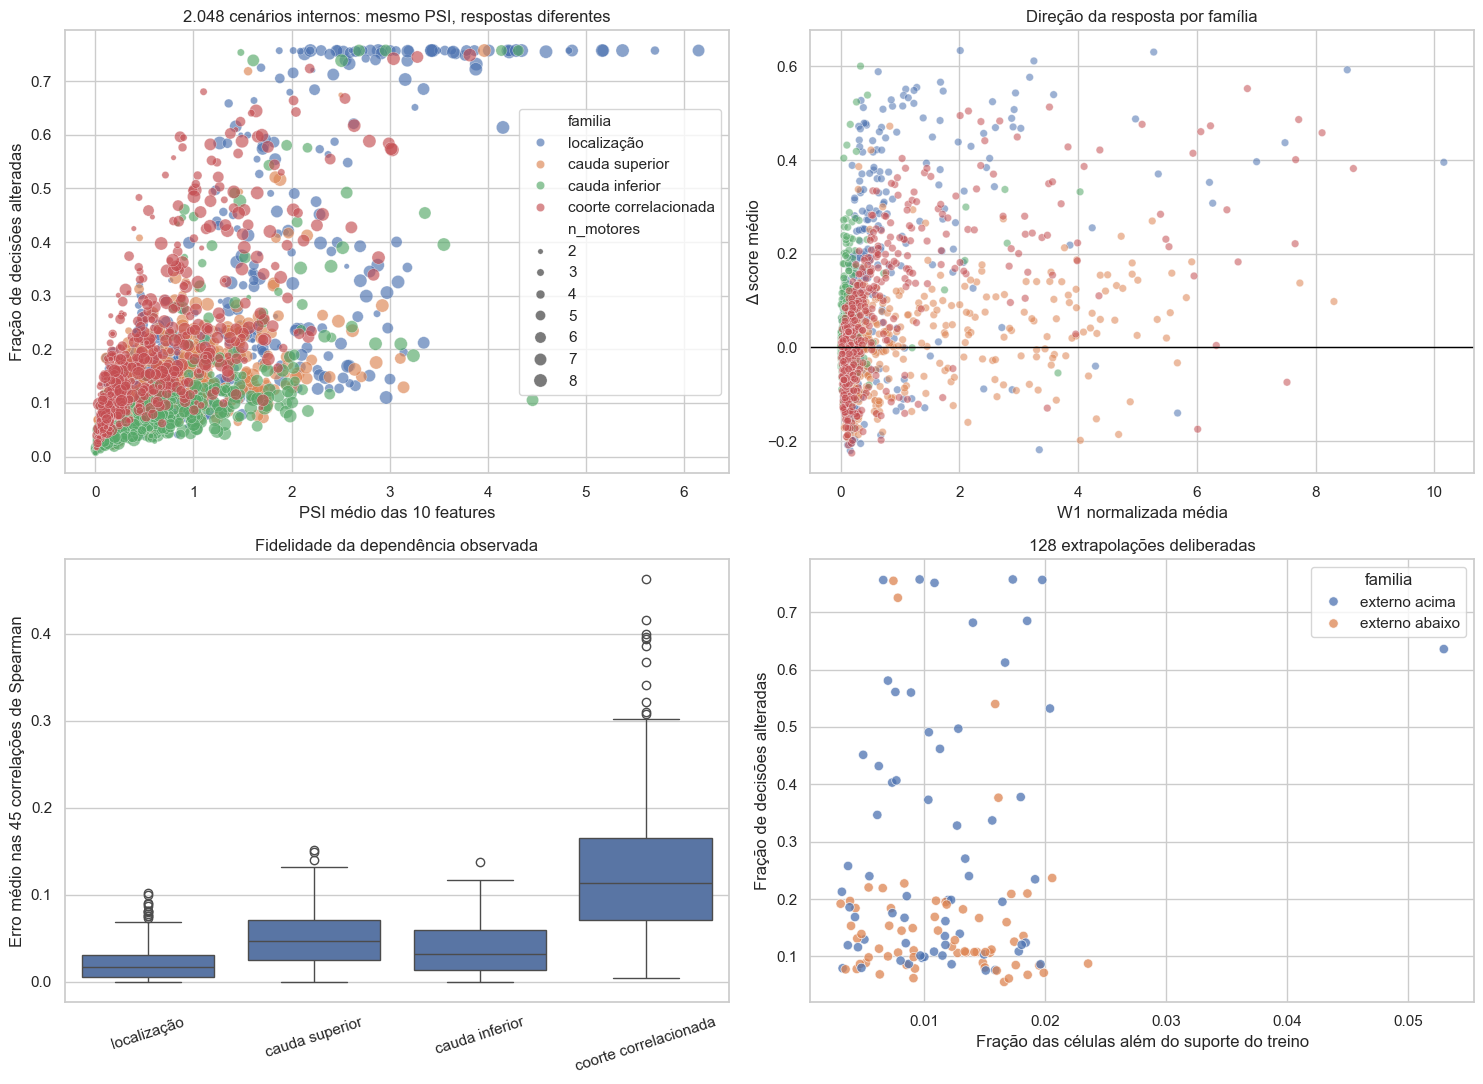

In [10]:
fig,axs=plt.subplots(2,2,figsize=(15,11))
sns.scatterplot(data=interno,x='psi_medio',y='flips_frac',hue='familia',
                size='n_motores',sizes=(15,90),alpha=.65,ax=axs[0,0])
axs[0,0].set(xlabel='PSI médio das 10 features',ylabel='Fração de decisões alteradas',
             title='2.048 cenários internos: mesmo PSI, respostas diferentes')
sns.scatterplot(data=interno,x='w1_norm_medio',y='delta_score_medio',hue='familia',
                alpha=.55,s=30,legend=False,ax=axs[0,1])
axs[0,1].axhline(0,color='black',lw=1)
axs[0,1].set(xlabel='W1 normalizada média',ylabel='Δ score médio',
             title='Direção da resposta por família')
sns.boxplot(data=interno,x='familia',y='corr_spearman_mae',ax=axs[1,0])
axs[1,0].tick_params(axis='x',rotation=18)
axs[1,0].set(xlabel='',ylabel='Erro médio nas 45 correlações de Spearman',
             title='Fidelidade da dependência observada')
sns.scatterplot(data=externo,x='fora_suporte_celulas_frac',y='flips_frac',
                hue='familia',alpha=.75,s=45,ax=axs[1,1])
axs[1,1].set(xlabel='Fração das células além do suporte do treino',
             ylabel='Fração de decisões alteradas',title='128 extrapolações deliberadas')
plt.tight_layout();plt.show()

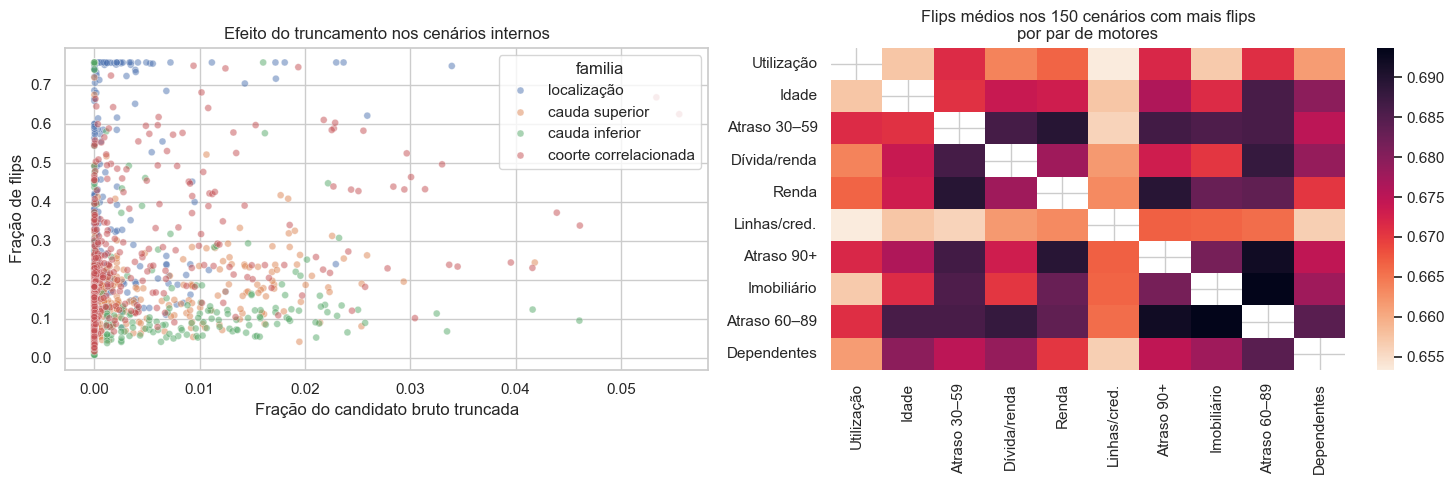

In [11]:
fig,axs=plt.subplots(1,2,figsize=(15,5))
sns.scatterplot(data=interno,x='truncamento_celulas_frac',y='flips_frac',
                hue='familia',alpha=.5,s=25,ax=axs[0])
axs[0].set(xlabel='Fração do candidato bruto truncada',ylabel='Fração de flips',
           title='Efeito do truncamento nos cenários internos')
top=interno.nlargest(150,'flips_frac')
pair_n=np.zeros((10,10),dtype=int)
pair_flip=np.zeros((10,10),dtype=float)
for row in top.itertuples():
    A=especificacoes[int(row.cenarios_sobol_aleatorio)]['A']
    for j in A:
        for k in A:
            if j!=k:
                pair_n[j,k]+=1;pair_flip[j,k]+=row.flips_frac
with np.errstate(invalid='ignore',divide='ignore'):
    pair_avg=np.where(pair_n>0,pair_flip/pair_n,np.nan)
np.fill_diagonal(pair_avg,np.nan)
sns.heatmap(pair_avg,xticklabels=FEATURE_SHORT,yticklabels=FEATURE_SHORT,
            cmap='rocket_r',ax=axs[1])
axs[1].set_title('Flips médios nos 150 cenários com mais flips\npor par de motores')
plt.tight_layout();plt.show()

## 8. Distribuições de resposta, sem limiar de parada

As linhas de `cs-test` não têm rótulos. Por isso, esta varredura apresenta **PSI, W1, alterações do score e reversões no corte 0,50** como respostas descritivas. Nenhuma fração de reversões ou diferença de score é usada para classificar um cenário como aprovado/reprovado. Uma taxa de reversão pequena também não prova desempenho preservado.

A tabela mostra mediana e percentil 95 por família, além dos cenários de maior reação. O erro médio de correlação de Spearman e as violações de domínio continuam visíveis para julgar a plausibilidade da simulação, sem corte arbitrário de fidelidade. A diferença entre `raw` e `sim` informa quanto da cauda foi truncado.

In [12]:
tbl=interno.groupby('familia').agg(
    n=('id','size'),psi_mediano=('psi_medio','median'),psi_p95=('psi_medio',lambda x:x.quantile(.95)),
    flips_mediano=('flips_frac','median'),flips_p95=('flips_frac',lambda x:x.quantile(.95)),
    movimento_abs_score_mediano=('movimento_abs_score_medio','median'),
    corr_mae_mediano=('corr_spearman_mae','median'),
    frac_truncada_mediana=('truncamento_celulas_frac','median'),
    dominio_violado_max=('dominio_basico_violado_linhas_frac','max'))
display(tbl.round(4))
display(interno.sort_values('flips_frac',ascending=False)[
    ['id','familia','n_motores','motores','psi_medio','w1_norm_medio',
     'corr_spearman_mae','truncamento_celulas_frac','flips_frac',
     'delta_score_medio']].head(15).round(4))
print('Erro de correlação de postos (p05/p50/p95):',
      interno.corr_spearman_mae.quantile([.05,.5,.95]).round(4).to_dict())
print('Cenários internos com alguma violação básica de domínio:',
      int((interno.dominio_basico_violado_linhas_frac>0).sum()),'de',len(interno))

,n,psi_mediano,psi_p95,flips_mediano,flips_p95,movimento_abs_score_mediano,corr_mae_mediano,frac_truncada_mediana,dominio_violado_max
familia,,,,,,,,,
cauda inferior,512,0.5522,2.0309,0.0740,0.3530,0.0558,0.0322,0.0000,0.2278
cauda superior,512,0.5608,1.8523,0.1222,0.2616,0.0891,0.0471,0.0000,0.0018
coorte correlacionada,512,0.5367,1.9567,0.1701,0.5683,0.1301,0.1131,0.0001,0.3098
localização,512,0.8794,3.4330,0.1600,0.7572,0.1253,0.0172,0.0000,0.2102


,id,familia,n_motores,motores,psi_medio,w1_norm_medio,corr_spearman_mae,truncamento_celulas_frac,flips_frac,delta_score_medio
44,INT0045,localização,8,RevolvingUtilizationOfUnsecuredLines | NumberO...,3.4248,0.6117,0.0263,0.0000,0.7572,0.4223
43,INT0044,localização,7,age | NumberOfTime30-59DaysPastDueNotWorse | M...,2.8032,5.3517,0.0249,0.0112,0.7572,0.3704
1151,INT1152,cauda inferior,6,RevolvingUtilizationOfUnsecuredLines | NumberO...,4.3115,0.3363,0.1175,0.0000,0.7572,0.6008
1176,INT1177,cauda inferior,7,RevolvingUtilizationOfUnsecuredLines | age | D...,2.6877,0.1639,0.0470,0.0160,0.7572,0.4763
1348,INT1349,cauda inferior,7,RevolvingUtilizationOfUnsecuredLines | age | N...,2.9591,0.2690,0.0748,0.0000,0.7572,0.5241
1120,INT1121,cauda inferior,6,RevolvingUtilizationOfUnsecuredLines | NumberO...,4.1390,0.4542,0.0990,0.0000,0.7572,0.5389
267,INT0268,localização,7,RevolvingUtilizationOfUnsecuredLines | DebtRat...,4.2011,7.4860,0.0596,0.0237,0.7572,0.4373
180,INT0181,localização,7,RevolvingUtilizationOfUnsecuredLines | age | N...,5.1765,1.6836,0.0217,0.0006,0.7572,0.5664
204,INT0205,localização,8,RevolvingUtilizationOfUnsecuredLines | age | N...,5.3735,1.1405,0.0443,0.0000,0.7572,0.5332
179,INT0180,localização,8,age | NumberOfTime30-59DaysPastDueNotWorse | M...,3.4406,1.0612,0.0302,0.0006,0.7572,0.5382


Erro de correlação de postos (p05/p50/p95): {0.05: 0.0022, 0.5: 0.0417, 0.95: 0.1767}
Cenários internos com alguma violação básica de domínio: 274 de 2048


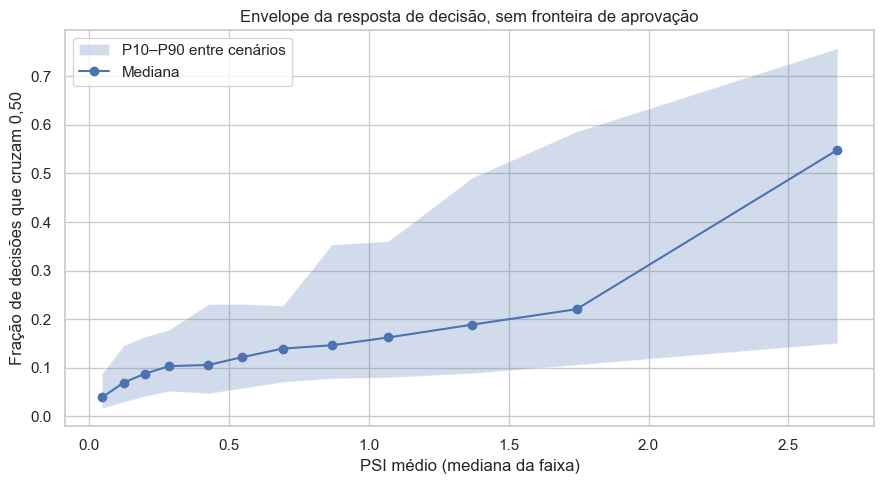

In [13]:
# As faixas por quantis de PSI servem apenas para visualizar o envelope de respostas.
q=np.unique(np.quantile(interno.psi_medio,np.linspace(0,1,13)))
interno['faixa_psi']=pd.cut(interno.psi_medio,bins=q,include_lowest=True,duplicates='drop')
envelope=interno.groupby('faixa_psi',observed=True).agg(
    psi_centro=('psi_medio','median'),
    flips_mediana=('flips_frac','median'),
    flips_p10=('flips_frac',lambda x:x.quantile(.1)),
    flips_p90=('flips_frac',lambda x:x.quantile(.9)),
    n=('id','size')).reset_index(drop=True)
fig,ax=plt.subplots(figsize=(9,5))
ax.fill_between(envelope.psi_centro.to_numpy(),envelope.flips_p10.to_numpy(),
                envelope.flips_p90.to_numpy(),alpha=.25,label='P10–P90 entre cenários')
ax.plot(envelope.psi_centro,envelope.flips_mediana,marker='o',label='Mediana')
ax.set(xlabel='PSI médio (mediana da faixa)',ylabel='Fração de decisões que cruzam 0,50',
       title='Envelope da resposta de decisão, sem fronteira de aprovação')
ax.legend();plt.tight_layout();plt.show()

### Dependência e coerência do gerador

Cada ponto mantém o diagnóstico contínuo do erro médio das 45 correlações de Spearman. A cor representa esse erro; valores menores indicam melhor reprodução das associações por postos observadas, mas não garantem coerência causal. A violação de domínio é mostrada separadamente. A inspeção de regras de produto deve ser feita com especialistas antes de interpretar um cenário sintético como plausível.

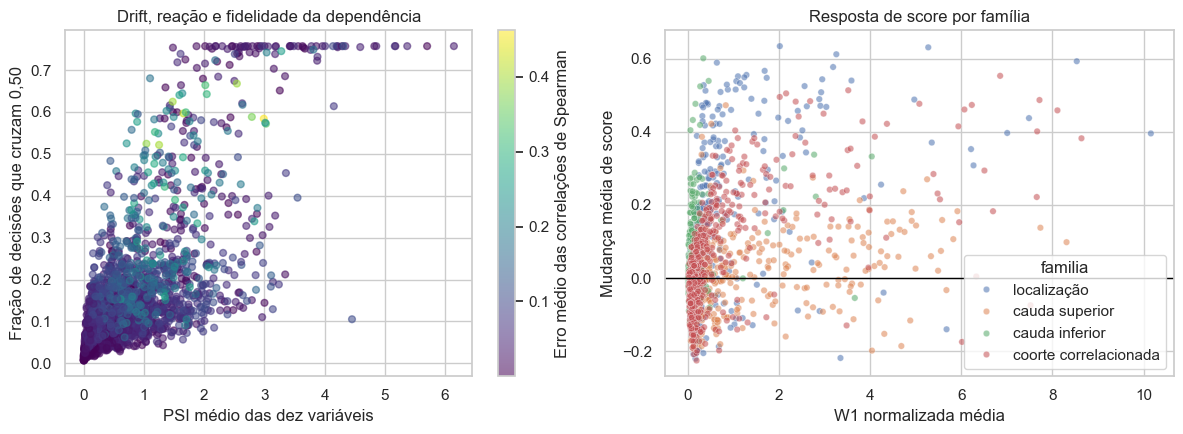

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sc=axes[0].scatter(interno['psi_medio'],interno['flips_frac'],
                   c=interno['corr_spearman_mae'],cmap='viridis',alpha=.55,s=24)
fig.colorbar(sc,ax=axes[0],label='Erro médio das correlações de Spearman')
axes[0].set(title='Drift, reação e fidelidade da dependência',
            xlabel='PSI médio das dez variáveis',ylabel='Fração de decisões que cruzam 0,50')
sns.scatterplot(data=interno,x='w1_norm_medio',y='delta_score_medio',
                hue='familia',alpha=.55,s=22,ax=axes[1])
axes[1].axhline(0,color='black',lw=1)
axes[1].set(title='Resposta de score por família',
            xlabel='W1 normalizada média',ylabel='Mudança média de score')
fig.tight_layout();plt.show()

## 9. Repetir oito cenários na população completa de `cs-test`

A seleção descritiva inclui maior PSI, maior fração de decisões que cruzam 0,50, maior movimento de score, menor PSI dentro dos cenários no decil superior de reversões, medianas da varredura e duas extrapolações externas (superior e inferior). Ela não usa um limiar de aprovação. O gerador, limites do treino, matriz da cópula e especificação Sobol ficam iguais; só a base passa de 5.000 para 101.503 linhas. As linhas completas aparecem no CSV com `escopo = completo_101503`. A seleção de extremos no piloto pode superestimar seus efeitos; a repetição testa a sensibilidade amostral, sem transformar desfechos desconhecidos em métricas de desempenho.

,id,psi_medio_5000,flips_frac_5000,delta_score_medio_5000,psi_medio_completo,flips_frac_completo,delta_score_medio_completo
0,INT0008,2.9241,0.7572,0.5553,3.4933,0.7580,0.5570
1,INT0166,5.7035,0.7572,0.6340,7.1716,0.7580,0.6351
2,INT0172,6.1483,0.7572,0.6118,7.4349,0.7580,0.6127
3,INT0759,0.1212,0.1250,0.0696,0.1169,0.1241,0.0694
4,INT1491,0.6240,0.1034,0.0882,0.8107,0.1035,0.0895
5,INT1751,0.3921,0.4252,0.2418,0.4323,0.4205,0.2406
6,EXT0001,2.4262,0.7572,0.5928,3.0964,0.7580,0.5936
7,EXT0070,2.4710,0.7548,0.3794,3.0948,0.7558,0.3800


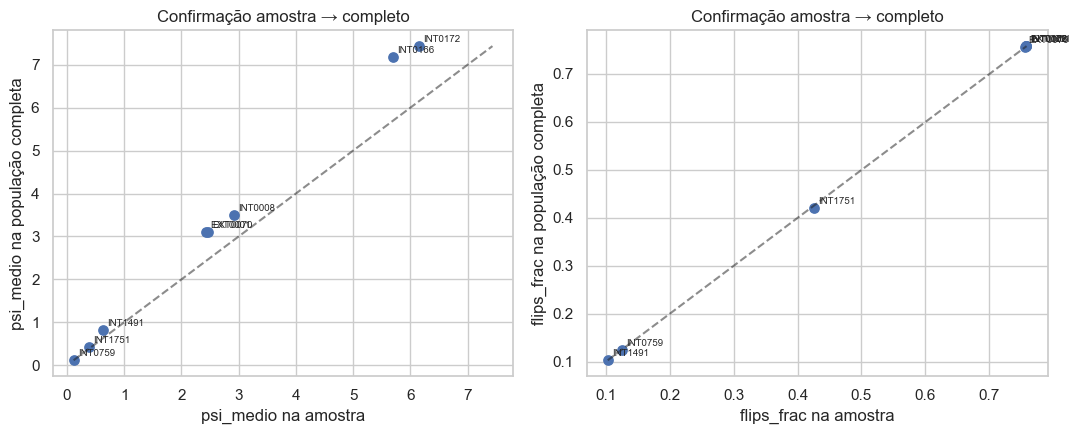

In [15]:
selec=[]
def adicionar(idx):
    i=int(idx)
    if i not in selec: selec.append(i)
adicionar(interno.psi_medio.idxmax())
adicionar(interno.flips_frac.idxmax())
adicionar(interno.delta_score_medio.abs().idxmax())
decil_superior=interno[interno.flips_frac>=interno.flips_frac.quantile(.9)]
adicionar(decil_superior.psi_medio.idxmin())
adicionar((interno.flips_frac-interno.flips_frac.median()).abs().idxmin())
adicionar((interno.psi_medio-interno.psi_medio.median()).abs().idxmin())
adicionar(externo.query("familia == 'externo acima'").flips_frac.idxmax())
adicionar(externo.query("familia == 'externo abaixo'").flips_frac.idxmax())
if len(selec)<8:
    for i in interno.sort_values('w1_norm_medio',ascending=False).index:
        adicionar(i)
        if len(selec)>=8: break
selec=selec[:8]

X_full_origem=cs_test[FEATURES].to_numpy(dtype=float)
X_full=np.clip(X_full_origem,lo,hi)
M_full=np.isnan(X_full)
Z_full=para_latente(X_full)
coorte_full=(Z_full@pc1)/max(np.std(Z_full@pc1),1e-8)
p_full=prever(X_full)
H_full=[contagem_hist(X_full[:,j],BINS_PSI[j]) for j in range(10)]
SORT_full=[np.sort(X_full[np.isfinite(X_full[:,j]),j]) for j in range(10)]
C_full=pd.DataFrame(X_full,columns=FEATURES).corr(method='spearman').fillna(0).to_numpy()
full_rows=[]
for i in selec:
    s=especificacoes[i]
    raw,sim=simular(s,X_full,Z_full,M_full,coorte_full)
    pf=prever(sim)
    full_rows.append(diagnosticos(s,raw,sim,pf,p_base=p_full,Xbase=X_full,
                                 missing=M_full,hist0=H_full,sorted0=SORT_full,
                                 corr0=C_full,escopo='completo_101503'))
confirmacao=pd.DataFrame(full_rows)
comp=interno[['id','psi_medio','flips_frac','delta_score_medio']].copy()
comp=pd.concat([comp,externo[['id','psi_medio','flips_frac','delta_score_medio']]])
comp=comp.merge(confirmacao[['id','psi_medio','flips_frac','delta_score_medio']],
                on='id',suffixes=('_5000','_completo'))
display(comp.round(4))
fig,axs=plt.subplots(1,2,figsize=(11,4.5))
for ax,v in zip(axs,['psi_medio','flips_frac']):
    ax.scatter(comp[f'{v}_5000'],comp[f'{v}_completo'],s=45)
    for r in comp.itertuples():
        ax.annotate(r.id,(getattr(r,f'{v}_5000'),getattr(r,f'{v}_completo')),
                    fontsize=7,xytext=(3,3),textcoords='offset points')
    lim=[min(comp[f'{v}_5000'].min(),comp[f'{v}_completo'].min()),
         max(comp[f'{v}_5000'].max(),comp[f'{v}_completo'].max())]
    ax.plot(lim,lim,'k--',alpha=.5)
    ax.set(xlabel=f'{v} na amostra',ylabel=f'{v} na população completa',
           title='Confirmação amostra → completo')
plt.tight_layout();plt.show()

## 10. Exportação e verificação

`resultados_multivariado_sintetico.csv` contém 2.176 cenários no piloto e oito repetições completas. Cada linha traz dez PSI, dez W1 normalizadas, dez frações truncadas e dez frações fora do suporte, além da mudança do score. Filtre por mecanismo, direção, PSI realizado, erro de dependência, suporte e resposta do modelo. Nenhum desses números determina sozinho a tolerância de **desempenho**: para isso, use cenários de reponderação com rótulos válidos e, depois, safras reais rotuladas.

In [16]:
export=pd.concat([resultados,confirmacao],ignore_index=True)
arquivo=BASE/'resultados_multivariado_sintetico.csv'
export.to_csv(arquivo,index=False,encoding='utf-8-sig')
assert len(export)==2184
assert export['id'].nunique()==2176
assert export.groupby('escopo').size().to_dict()=={'amostra_5000':2176,'completo_101503':8}
assert export.query("regime_suporte == 'interno_truncado'")['fora_suporte_celulas_frac'].eq(0).all()
assert export.query("regime_suporte == 'externo_sem_truncamento'")['fora_suporte_celulas_frac'].gt(0).all()
assert export['faltantes_preservados'].all() and export['discretas_inteiras'].all()
print('Arquivo:',arquivo,'| linhas:',len(export),'| colunas:',len(export.columns))
print('Fração interna com truncamento efetivo:',
      round(float((interno.truncamento_celulas_frac>0).mean()),3))
print('Faixa de PSI médio nos internos:',
      interno.psi_medio.quantile([0,.1,.5,.9,1]).round(4).to_dict())
print('Faixa de flips nos internos:',
      interno.flips_frac.quantile([0,.1,.5,.9,1]).round(4).to_dict())
print('Relação entre métricas: correlação Pearson(PSI médio, flips)=',
      round(float(interno[['psi_medio','flips_frac']].corr().iloc[0,1]),3))

Arquivo: .\results\tables\resultados_multivariado_sintetico.csv | linhas: 2184 | colunas: 82
Fração interna com truncamento efetivo: 0.512
Faixa de PSI médio nos internos: {0.0: 0.0003, 0.1: 0.097, 0.5: 0.6244, 0.9: 1.9473, 1.0: 6.1483}
Faixa de flips nos internos: {0.0: 0.0066, 0.1: 0.0457, 0.5: 0.1249, 0.9: 0.3983, 1.0: 0.7572}
Relação entre métricas: correlação Pearson(PSI médio, flips)= 0.713


## 11. Método adicional: triagem Morris com SALib sobre controles do gerador

O método dos efeitos elementares de Morris investiga, com poucas avaliações, quais **controles independentes do procedimento de simulação** mais influenciam a fração de decisões alteradas. Aplicá-lo diretamente às dez variáveis de crédito como se fossem entradas independentes quebraria a dependência que estamos tentando preservar. Aqui fixamos um conjunto de motores (utilização, dívida/renda, renda, atraso de 30–59 dias) e variamos quatro *botões* do gerador: intensidade global, ênfase no lado positivo da primeira componente latente (não um segmento de risco medido), fração da propagação condicional e parcela de extrapolação bruta mantida após o truncamento. São 20 trajetórias de cinco pontos, total de 100 avaliações no mesmo subconjunto de 5.000 linhas.

`μ*` é a média absoluta dos efeitos elementares e serve para triagem **dentro dos intervalos escolhidos**, não como importância causal das variáveis originais. `σ` sugere não linearidade/interações entre controles. Se `σ` for alto, a conclusão depende do ponto de partida da trajetória. Fonte: [documentação SALib Morris](https://salib.readthedocs.io/en/latest/_modules/SALib/analyze/morris.html) e [Campolongo et al., desenho de efeitos elementares](https://publications.jrc.ec.europa.eu/repository/handle/JRC37360).

,controle,mu_star,sigma,mu_star_ic95
0,intensidade_global,0.6719,0.0887,0.0378
1,enfase_coorte,0.0619,0.0965,0.0463
2,fracao_propagacao,0.0387,0.0384,0.0163
3,fracao_extrapolacao,0.0000,0.0000,0.0000


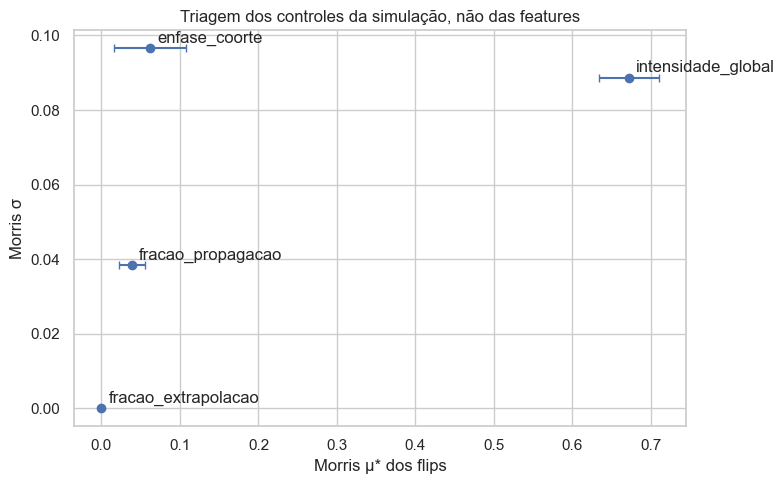

Intervalo de flips nas 100 avaliações Morris: 0.0 0.7514


In [17]:
from SALib.sample import morris as morris_sample
from SALib.analyze import morris as morris_analyze

problema={'num_vars':4,
          'names':['intensidade_global','enfase_coorte','fracao_propagacao','fracao_extrapolacao'],
          'bounds':[[0,2.5],[0,1],[0,1],[0,1]]}
desenho=morris_sample.sample(problema,N=20,num_levels=4,seed=SEED+99)
assert desenho.shape==(100,4)
A=np.array([0,2,3,4]);B=np.array([j for j in range(10) if j not in A])
beta=R[np.ix_(B,A)]@np.linalg.inv(R[np.ix_(A,A)])
Y=[]
for intensidade,enfase,propagacao,extrapolacao in desenho:
    dA=intensidade*np.array([1,.45,.80,-.55])[None,:]
    dA=dA*(1+enfase*expit(2*coorte))[:,None]
    dz=np.zeros_like(Z0)
    dz[:,A]=dA
    dz[:,B]=propagacao*(dA@beta.T)
    raw=inversa_empirica_bruta(Z0+dz,M0)
    clipped=np.clip(raw,lo,hi)
    sim=clipped+extrapolacao*(raw-clipped)
    sim[M0]=np.nan
    pred=prever(sim)>=CUTOFF
    Y.append(np.mean(pred!=(p0>=CUTOFF)))
Y=np.array(Y)
Si=morris_analyze.analyze(problema,desenho,Y,num_levels=4,
                          num_resamples=200,seed=SEED+100)
morris_tab=pd.DataFrame({'controle':problema['names'],'mu_star':Si['mu_star'],
                         'sigma':Si['sigma'],'mu_star_ic95':Si['mu_star_conf']})
display(morris_tab.sort_values('mu_star',ascending=False).round(4))
fig,ax=plt.subplots(figsize=(8,5))
ax.errorbar(morris_tab.mu_star,morris_tab.sigma,
            xerr=morris_tab.mu_star_ic95,fmt='o',capsize=3)
for r in morris_tab.itertuples():
    ax.annotate(r.controle,(r.mu_star,r.sigma),xytext=(5,4),textcoords='offset points')
ax.set(xlabel='Morris μ* dos flips',ylabel='Morris σ',
       title='Triagem dos controles da simulação, não das features')
plt.tight_layout();plt.show()
print('Intervalo de flips nas 100 avaliações Morris:',float(Y.min()),float(Y.max()))